# 1. Live Stream Analysis: Preparer using Command Line Interface (CLI)

This tutorial shows how to run the `live_stream_analysis preparer` sub-command using the command-line interface (CLI).

This step produces the data for the following three files:
1. **Pixel geometry CSV**: one row per detector pixel with its time-of-flight (TOF) → momentum transfer (Q) constant, from an instrument definition (IDF) and, optionally, a diffraction calibration.
2. **Background CSV**: I(Q) of the empty sample can, reduced from NeXus event files.
3. **Normalization CSV**: I(Q) of a vanadium rod with its small Bragg peaks stripped, used to
   divide out the detector and spectrum response.

After this data is created, the next step is to run the `live_stream_analysis analyze` sub-commands for sample data.

This `preparer` step is the same whichever sample source you analyze afterwards (NeXus file, ADARA file or
live ADARA stream), so there is one preparer notebook per method and not per source.

**Runtime:** seconds using laptop-type computer

**CLI Commands:** Shell cells (`%%bash`) below run exactly what you would type in a terminal.

## Data used in these walkthroughs

| Role | Run (ONCat title) | Tutorial file, in `tests/data/tutorial/` | Full run |
| --- | --- | --- | --- |
| Sample, NeXus | NOM_244114 (Diamond at temperature 299.99 K) | `NOM_244114.nxs.h5`: first 0.67 s, 4.8 MB | 4:48, 0.40 C: `/SNS/NOM/IPTS-37098/nexus/NOM_244114.nxs.h5` (3.3 GB) |
| Sample, ADARA | 244114, the same run as streamed by the SMS | `m00000001-f00000001-run-244114.adara`: the same 0.67 s, closed by the run's END_RUN, 7.9 MB | 16 files, 3.2 GB: `20260619-140639.403016382-run-244114/` |
| Background | NOM_243710 (MT_6mm_PAC: empty PAC06 can) | `NOM_243710.nxs.h5`: first 2.5 s, 3.0 MB | 24:02, 2.00 C, plus NOM_243711 (24:03, 2.00 C): `/SNS/NOM/IPTS-37412/nexus/NOM_243710.nxs.h5` |
| Normalization | NOM_243712 (V_rod: vanadium rod) | `NOM_243712.nxs.h5`: first 0.5 s, 3.2 MB | 24:03, 2.00 C: `/SNS/NOM/IPTS-37412/nexus/NOM_243712.nxs.h5` (12 GB) |
| Calibration | 243451, 2026-06-09 | `tests/data/calibration/NOMAD_243451_2026-06-09_shifter.h5` | the same file (located at `/SNS/NOM/shared/autoreduce/calibration/NOMAD_243451_2026-06-09_shifter.h5`) |

The diamond sample is run 244114 (IPTS-37098, 2026-06-19) in both formats: the NeXus file written
when the run ended, and the ADARA packets the SMS streamed while it ran.

The background and vanadium are IPTS-37412 standards from 2026-06-12, measured with the same PAC06 can type.

## Setup

This cell checks that the environment running this notebook has `live_stream_analysis` installed and its command on
`PATH`.
It also moves to the repository root, so every path below is the one you would type in a terminal
there.

*NOTE*: If it fails, follow "Installing" in `notebooks/README.md`.

In [1]:
import os
import sys
from pathlib import Path

# The walkthrough needs live_stream_analysis installed in the environment this kernel runs in.
try:
    import live_stream_analysis
except ModuleNotFoundError as error:
    raise ModuleNotFoundError(
        f"live_stream_analysis is not installed for this kernel ({sys.executable}). Follow "
        "'Installing' in notebooks/README.md, then start Jupyter from that environment."
    ) from error
print(f"live_stream_analysis {live_stream_analysis.__version__} on Python {sys.version.split()[0]}: {sys.executable}")

# The shell cells run the `live_stream_analysis` command, so it must be on PATH as well.
import shutil

command = shutil.which("live_stream_analysis")
if command is None:
    raise RuntimeError(
        "The live_stream_analysis command is not on PATH. Start Jupyter from the environment you "
        "installed it in, with that environment activated (see 'Installing' in notebooks/README.md)."
    )
print(f"live_stream_analysis command: {command}")

# Every path below is relative to the repository root, as it would be in a terminal there.
REPO_ROOT = next((path for path in [Path.cwd(), *Path.cwd().parents] if (path / "tests/data/tutorial").is_dir()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Open this notebook from a clone of the live_stream_analysis repository.")
os.chdir(REPO_ROOT)
OUTPUT_DIR = Path("notebooks/output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Working directory: {Path.cwd()}")
print(f"Output directory: {OUTPUT_DIR.absolute()}")

live_stream_analysis 0.2.0 on Python 3.12.3: /home/ntm/projects/illumine/live_stream_analysis/.venv/bin/python3
live_stream_analysis command: /home/ntm/projects/illumine/live_stream_analysis/.venv/bin/live_stream_analysis
Working directory: /home/ntm/projects/illumine/live_stream_analysis
Output directory: /home/ntm/projects/illumine/live_stream_analysis/notebooks/output


## Step 1: pixel geometry from the instrument definition file (IDF) and calibration file

This step creates a table where each row is a pixel ID, called `pixel id`, and the main column `TOF-to-Q matrix element` is a constant, $C_{TOF-to-Q}$, that converts a time-of-flight ($TOF$) to momentum transfer ($Q$) for that pixel, such that:

$$
  Q = \frac{C_{TOF-to-Q}}{TOF}
$$

#### Optional: Calibration File

By default, we will just use the IDF geometry to calculate the `TOF-to-Q matrix element` constant, $C_{TOF-to-Q}$, for the conversion.

However, if a `--calibration-file` is passed in, it replaces each pixel's ideal TOF→Q constant from IDF with the calibrated DIFC, and then will use the additional `difc`, `difa`, `tzero` and `use` columns.
Pixels with `use = 0` are masked by the analyzer.

The same CSV serves both sources (NeXus file or ADARA file / stream).
Only the analyzer's `--tof-tick-us` differs: 1.0 for NeXus, whose
TOF is in µs, and 0.1 for ADARA, whose TOF is in 100 ns ticks. 

In [2]:
%%bash
live_stream_analysis preparer \
    --idf-file tests/data/idf/NOMAD_Definition.xml \
    --calibration-file tests/data/calibration/NOMAD_243451_2026-06-09_shifter.h5 \
    --pixel-geometry-csv notebooks/output/pixel_geometry_calibrated.csv \
    --iq-csv notebooks/output/synthetic_iq.csv

echo ""
echo "=== Pixel Geometry CSV ==="
head -3 notebooks/output/pixel_geometry_calibrated.csv
echo "..."
tail -3 notebooks/output/pixel_geometry_calibrated.csv


Loaded IDF: /home/ntm/projects/illumine/live_stream_analysis/tests/data/idf/NOMAD_Definition.xml
Det

ector pixels: 101376
Pixel geometry CSV: /home/ntm/projects/illumine/live_stream_analysis/notebooks/

output/pixel_geometry_calibrated.csv
I(Q) CSV: /home/ntm/projects/illumine/live_stream_analysis/note

books/output/synthetic_iq.csv (400 bins)
Q-matrix scale applied: 1.0
Calibration file: /home/ntm/pro

jects/illumine/live_stream_analysis/tests/data/calibration/NOMAD_243451_2026-06-09_shifter.h5


...

2628257,0.00000000,0.00000000,0


...


101373,2.60935147,15.03263191,9186.69855885,1462.10848634,0.00000000,0.00000000,0
101374,2.61081253

,15.15156371,9259.59346493,1473.71007096,0.00000000,0.00000000,0
101375,2.61229612,15.27126940,9332

.96791975,1485.38797815,0.00000000,0.00000000,0


## Step 2: background from the empty-can runs

This step creates the background, $I_{background}$, of the sample data we will subtract off from the sample measurement, $I_{sample}$:

$$
  I_{sample}(Q) - I_{background}(Q)
$$

The "background" mode is set by `--mode background`.

Repeat `--nexus-file` to combine multiple background runs. Counts are summed, and so are the recorded proton charge and
duration.

The output is set by `--reduction-output-csv`

The range for Q can be set by `--q-min` and `--q-max`.

In [3]:
%%bash
time live_stream_analysis preparer \
    --mode background \
    --nexus-file tests/data/tutorial/NOM_243710.nxs.h5 \
    --reduction-output-csv notebooks/output/background.csv \
    --q-min 0.0 \
    --q-max 40.0

echo ""
echo "=== Background CSV ==="
head -3 notebooks/output/background.csv
echo "..."
tail -3 notebooks/output/background.csv

Reduction mode: background
Input NeXus files: 1
Total counts: 379511
Total proton charge (pC): 34732

96320.0
Total duration (s): 2.5
Reduction CSV: /home/ntm/projects/illumine/live_stream_analysis/note

books/output/background.csv



real	0m2.175s
user	0m3.493s
sys	0m0.153s


=== Background CSV ===


Q value,I(Q),Error I(Q),Proton charge (pC),Duration (s)
0.01000000,0.00000000,0.00000000,3473296320

.00000000,2.50000000
0.03000000,0.00000000,0.00000000,3473296320.00000000,2.50000000
...


39.95000000,36.00000000,6.00000000,3473296320.00000000,2.50000000
39.97000000,35.00000000,5.9160797

8,3473296320.00000000,2.50000000


## Step 3: normalization from the vanadium rod

This step creates the normalization, $I_{normalization}$, of the sample data we will normalize sample measurement by.

$$
  I_{sample}(Q) / I_{normalization}(Q)
$$

If we also have the background, $I_{background}$, from the previous step 2, then we will have:

$$
  ( I_{sample}(Q) - I_{background}(Q) ) / I_{normalization}(Q)
$$

The "normalization" mode is set by `--mode normalization`.

For processing the normalization run, the vanadium pattern weak Bragg peaks are smoothed by replacing points more than `--peak-z-threshold` standard deviations above the smoothed baseline. And `--peak-window` is the smoothing window in bins.

In [4]:
%%bash
time live_stream_analysis preparer \
    --mode normalization \
    --nexus-file tests/data/tutorial/NOM_243712.nxs.h5 \
    --reduction-output-csv notebooks/output/normalization.csv \
    --q-min 0.0 \
    --q-max 40.0 \
    --peak-window 31 \
    --peak-z-threshold 3.0

echo ""
echo "=== Normalization CSV ==="
head -3 notebooks/output/normalization.csv
echo "..."
tail -3 notebooks/output/normalization.csv

Reduction mode: normalization
Input NeXus files: 1
Total counts: 482517
Total proton charge (pC): 69

3417800.0
Total duration (s): 0.5
Reduction CSV: /home/ntm/projects/illumine/live_stream_analysis/no

tebooks/output/normalization.csv



real	0m2.184s
user	0m3.522s
sys	0m0.136s


=== Normalization CSV ===


Q value,I(Q),Error I(Q),Proton charge (pC),Duration (s)
0.01000000,1.80000000,1.34164079,693417800.

00000000,0.50000000
0.03000000,3.13333333,1.77012241,693417800.00000000,0.50000000


...


39.95000000,26.26666667,6.55743852,693417800.00000000,0.50000000
39.97000000,23.53333333,6.40312424

,693417800.00000000,0.50000000
39.99000000,21.73333333,6.78232998,693417800.00000000,0.50000000


## Step 4: Look at what was produced

Background and vanadium divided by their own proton charge, which is the scale the analyzer puts
them on before subtracting and dividing.

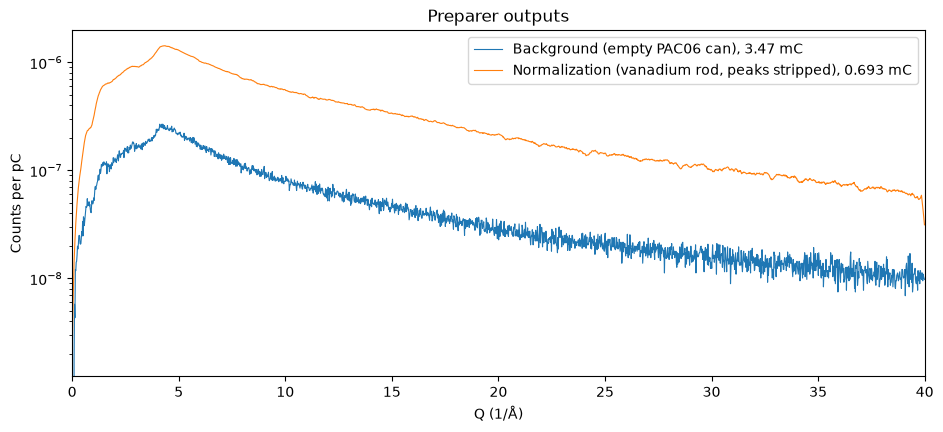

In [5]:
import matplotlib.pyplot as plt

from live_stream_analysis.notebook import read_csv

background = read_csv(OUTPUT_DIR / "background.csv")
normalization = read_csv(OUTPUT_DIR / "normalization.csv")

fig, ax = plt.subplots(figsize=(11, 4.5))
for label, table in [("Background (empty PAC06 can)", background), ("Normalization (vanadium rod, peaks stripped)", normalization)]:
    charge = table["Proton charge (pC)"][0]
    ax.plot(table["Q value"], table["I(Q)"] / charge, linewidth=0.8, label=f"{label}, {charge / 1e9:.3g} mC")
ax.set(xlim=(0, 40), xlabel="Q (1/Å)", ylabel="Counts per pC", yscale="log", title="Preparer outputs")
ax.legend()
plt.show()

## Step 5: diamond reference reflections

Not a preparer output, but the analyze notebooks mark these expected peak positions on the result
as an absolute check of the Q axis.

In [6]:
%%bash
python scripts/live_comparison/diamond_reference.py \
    --q-max 40 \
    --output-csv notebooks/output/diamond_reflections.csv

a = 3.56712 A -> 124 allowed reflections up to Q = 40.0
Wrote /home/ntm/projects/illumine/live_strea

m_analysis/notebooks/output/diamond_reflections.csv

hkl                d (A)   Q (1/A)  mult    rel

 I
111               2.0595    3.0509     8   100.00
220               1.2612    4.9820    12    41.

37
311               1.0755    5.8420    24    21.62
400               0.8918    7.0457     6     5.

01
331               0.8184    7.6778    24     7.02
422               0.7281    8.6291    24     8.

63
333/511           0.6865    9.1526    32     4.49
440               0.6306    9.9641    12     2.

35
531               0.6030   10.4207    48     3.89
620               0.5640   11.1402    24     2.

92
533               0.5440   11.5504    24     1.25
444               0.5149   12.2035     8     0.

65


# Next Step...
Pick an analyze notebook: `02_analyze_nexus_*`, `03_analyze_adara_file_*` or
`04_analyze_adara_stream_*`.

# Notes / Details

### Test Data
By default every notebook uses the tutorial dataset in `tests/data/tutorial/`.
The files in these datasets are the first part of a full run, cut by time and small enough to keep in the repository and to run anywhere in seconds.
Reduced together, it reproduces the full-data I(Q) to 95.9 %, with every strong diamond peak within 0.002 1/Å of its full-data position (see `tests/data/tutorial/README.md`).

To use the full runs, set `FULL_DATA = True` in a Python notebook's setup cell; each CLI notebook
lists the paths to swap in. They need `nexus_files/` in the repository root and the carbon NFS
share next to it (see the "ADARA data on ORC NFS shares" section of `docs/reference.md`).

**Runtime:** seconds on the tutorial data. On the full runs, the preparer takes about a minute,
mostly reading the 12 GB vanadium file.

### Normalization for Length of Measurement / Run
The proton charge and duration of the runs are included in the background and normalization CSV files.
This allows us to normalize background and normalization to the sample data by how long each was measured.
When the files produced here are used with sample data in `live_stream_analysis analyze`, each dataset is divided by its own proton charge (the default) or, with `--normalize-by time`, its duration, to perform this normalization.

### Calibration Details

On the full run 244114, ten days after this calibration, the calibrated geometry puts the diamond
reflections a nearly constant 0.43 % low in Q (mean −0.050 1/Å), against about 0.67 % low
uncalibrated. Mantid, given the same calibration, produces an identical histogram (see
`scripts/live_comparison/README.md`), so the offset is the calibration, not the conversion.
NOMAD's sample position moves whenever the sample environment is swapped, and diamond is itself
the usual calibrant, so a calibration made from these runs would remove that offset.

### Calibration NOT Applied to Background and Vanadium

The background and vanadium reductions use the instrument geometry embedded in each NeXus file,
**without** the calibration, while the sample is histogrammed with the calibrated geometry from
step 1. The two Q axes therefore differ by the calibration's correction, about 0.75 % on NOMAD at
this time. The vanadium is smooth after peak stripping, so this matters little there; features in
the background can land a fraction of a bin away from the matching features in the sample.

